# DGCA domestic airlines: cleaning and first analysis
Run the cells in order, in the same Jupyter session as the download notebook (or at least from the folder that contains `data/`). Reads `data/interim/`, writes `data/clean/`.

## 1. Load the interim table

In [1]:
# BLOCK 1: load the interim table
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TODAY = globals().get("TODAY", pd.Timestamp.today().date().isoformat())

# Locate project directories
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "data/interim").is_dir()), None)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find project data/interim.")

INTERIM = PROJECT_ROOT / "data/interim"
CLEAN = PROJECT_ROOT / "data/clean"
CLEAN.mkdir(parents=True, exist_ok=True)

# Load the latest parsed DGCA dataset
files = sorted(INTERIM.glob("dgca_domestic_airline_monthly_*.csv"))
if not files:
    raise FileNotFoundError(f"No parsed DGCA CSV found in {INTERIM}.")

src = files[-1]
raw = pd.read_csv(src)

# Explicitly define the 16 metric columns
METRICS = [
    "Aircraft Number", "Aircraft Hours", "Aircraft Kilometres",
    "Passenger Number", "Passenger Kilometers", "Seat Kilometers",
    "Passenger Load Factor", "Freight", "Mail", "Total Cargo",
    "Passenger Tonne Kilometer", "Mail Tonne Kilometer",
    "Freight Tonne Kilometer", "Total Tonne Kilometer",
    "Available Tonne Kilometer", "Weight Load Factor"
]

KEYS = ["Type", "Airline", "Year", "Month"]
required = KEYS + ["Source File", "Source Sheet"] + METRICS

missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Input table is missing expected columns: {missing}")

# Convert metric columns to numeric values
for c in METRICS:
    raw[c] = pd.to_numeric(
        raw[c].astype("string").str.replace(",", "", regex=False)
        .str.strip().replace("-", pd.NA),
        errors="coerce"
    )

# Validate year and month
raw["Year"] = pd.to_numeric(raw["Year"], errors="coerce")
raw["Month"] = pd.to_numeric(raw["Month"], errors="coerce")

if raw[["Year", "Month"]].isna().any().any():
    raise ValueError("Year or Month contains missing/non-numeric values.")

raw["Year"] = raw["Year"].astype(int)
raw["Month"] = raw["Month"].astype(int)

if not raw.Month.between(1, 12).all():
    raise ValueError("Month values must be between 1 and 12.")

print("Input:", src.name, "| Shape:", raw.shape)
print("Source files:", raw["Source File"].nunique())
print("Source sheets:", raw[["Source File", "Source Sheet"]].drop_duplicates().shape[0])
print("Years:", raw.Year.min(), "-", raw.Year.max())
print("Traffic types:", sorted(raw.Type.dropna().unique()))

display(raw.head(3))

Input: dgca_domestic_airline_monthly_2026-11-01.csv | Shape: (5844, 22)
Source files: 142
Source sheets: 142
Years: 2017 - 2026
Traffic types: ['NonScheduledDomestic', 'NonScheduledInternational', 'ScheduledDomestic', 'ScheduledInternational']


,Type,Airline,Year,Month,Source File,Source Sheet,Aircraft Number,Aircraft Hours,Aircraft Kilometres,Passenger Number,...,Passenger Load Factor,Freight,Mail,Total Cargo,Passenger Tonne Kilometer,Mail Tonne Kilometer,Freight Tonne Kilometer,Total Tonne Kilometer,Available Tonne Kilometer,Weight Load Factor
0,NonScheduledDomestic,AIX Connect,2024,1,aix connect 24.xlsx,Monthly_Template,6.0,5.9,5.087,896.0,...,85.033218,<NA>,<NA>,<NA>,59.2284,<NA>,<NA>,59.2284,101.74,58.215451
1,NonScheduledDomestic,AIX Connect,2024,2,aix connect 24.xlsx,Monthly_Template,3.0,3.0,3.0,349.0,...,73.966942,<NA>,<NA>,<NA>,27.0,<NA>,<NA>,27.0,54.0,50.0
2,NonScheduledDomestic,AIX Connect,2024,3,aix connect 24.xlsx,Monthly_Template,9.0,13.0,4.178,1114.0,...,68.135206,<NA>,<NA>,<NA>,38.4303,<NA>,<NA>,38.4303,83.56,45.991264


## 2. Where are the holes?
Separates empty template rows from genuinely missing values, and draws when each airline operates.

Row classification:
 row_kind                   empty_template  live  live_but_no_pax   All
Type                                                                  
NonScheduledDomestic                  759   761                4  1524
NonScheduledInternational             957   288               15  1260
ScheduledDomestic                     278  1424                2  1704
ScheduledInternational                816   540                0  1356
All                                  2810  3013               21  5844

Empty-template rows: 2,810 (48.1%)

Missing share by metric among non-empty rows:


Type,NonScheduledDomestic,NonScheduledInternational,ScheduledDomestic,ScheduledInternational
Aircraft Number,0.0,0.007,0.001,0.0
Aircraft Hours,0.003,0.007,0.003,0.0
Aircraft Kilometres,0.0,0.007,0.001,0.0
Passenger Number,0.005,0.05,0.001,0.0
Passenger Kilometers,0.007,0.05,0.003,0.0
Seat Kilometers,0.005,0.046,0.002,0.0
Passenger Load Factor,0.107,0.165,0.013,0.011
Freight,0.192,0.063,0.138,0.031
Mail,0.391,0.568,0.287,0.243
Total Cargo,0.188,0.059,0.138,0.031


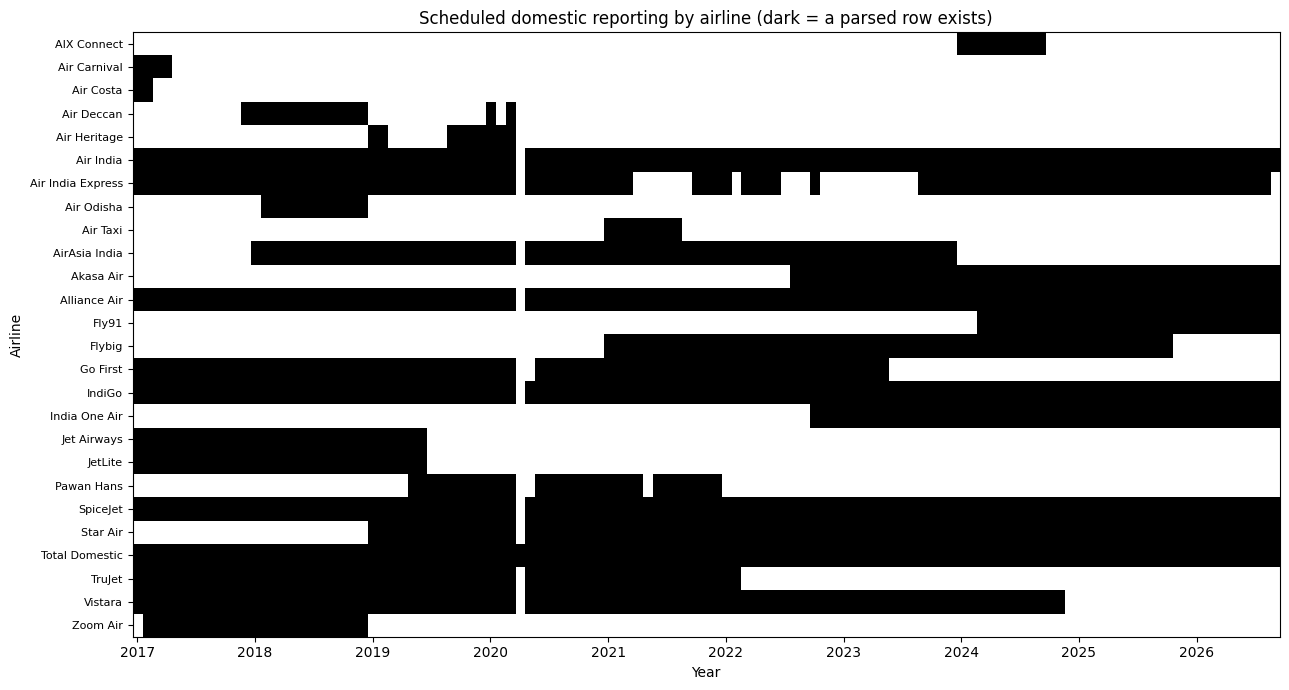

In [2]:
# BLOCK 2: where are the holes? (empty template rows vs real missing values)
# Classify rows based on whether metric values are available
raw["row_kind"] = np.where(
    raw[METRICS].isna().all(axis=1),
    "empty_template",
    np.where(raw["Passenger Number"].isna(), "live_but_no_pax", "live")
)

print("Row classification:\n", pd.crosstab(
    raw.Type, raw.row_kind, margins=True
).to_string())

empty_count = (raw.row_kind == "empty_template").sum()
print(f"\nEmpty-template rows: {empty_count:,} ({empty_count / len(raw):.1%})")

# Examine missingness among non-empty rows
live = raw[raw.row_kind != "empty_template"]

print("\nMissing share by metric among non-empty rows:")
display(live.groupby("Type")[METRICS].agg(lambda s: s.isna().mean()).T.round(3))

# Visualise monthly reporting by airline
sd = live[live.Type == "ScheduledDomestic"].copy()
sd["Date"] = pd.to_datetime(dict(year=sd.Year, month=sd.Month, day=1))

pres = sd.assign(reported=1).pivot_table(
    index="Airline", columns="Date", values="reported", aggfunc="max"
)

if not pres.empty:
    fig, ax = plt.subplots(figsize=(13, 7))
    ax.imshow(pres.notna().astype(int).values, aspect="auto",
              cmap="Greys", interpolation="nearest")

    ax.set_yticks(range(len(pres)))
    ax.set_yticklabels(pres.index, fontsize=8)

    ticks = [i for i, d in enumerate(pres.columns) if d.month == 1]
    ax.set_xticks(ticks)
    ax.set_xticklabels([pres.columns[i].year for i in ticks])

    ax.set_title("Scheduled domestic reporting by airline (dark = a parsed row exists)")
    ax.set_xlabel("Year")
    ax.set_ylabel("Airline")

    plt.tight_layout()
    plt.show()
else:
    print("No ScheduledDomestic rows available for the reporting heatmap.")

## 3. Cleaning steps (each one logged)
Drop empty rows, keep domestic, set Total Domestic aside, drop cargo columns, build the date, check duplicates, map brands to groups.

In [3]:
# BLOCK 3: cleaning steps 1-5 (each logged with rows affected)
# Initialise cleaning log
log = []

def step(name, before, after, note=""):
    log.append({
        "step": name,
        "rows_before": int(before),
        "rows_after": int(after),
        "rows_affected": int(before - after),
        "note": note
    })
    print(f"{name}: {before:,} -> {after:,} | {note}")

df = raw.drop(columns="row_kind").copy()

# Standardise airline labels for matching
df["Airline"] = df["Airline"].astype("string").str.strip()
df["Airline_key"] = (
    df["Airline"].str.casefold()
    .str.replace(r"[_-]+", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Remove completely empty template rows
n = len(df)
df = df[~df[METRICS].isna().all(axis=1)].copy()
step("remove empty template rows", n, len(df), "All 16 metric fields were empty.")

# Retain domestic traffic sections
n = len(df)
df = df[df.Type.isin(["ScheduledDomestic", "NonScheduledDomestic"])].copy()
step("retain domestic traffic sections", n, len(df), "International traffic sections excluded.")

# Separate DGCA aggregate rows for reconciliation
total_mask = df.Airline_key.eq("total domestic")
totals = df[total_mask].drop(columns="Airline_key").copy()

n = len(df)
df = df[~total_mask].copy()
step("separate Total Domestic aggregate", n, len(df), "Aggregate retained separately for reconciliation.")

# Keep the core analysis columns
KEEP = [
    "Type", "Airline", "Year", "Month", "Source File", "Source Sheet",
    "Aircraft Number", "Aircraft Hours", "Aircraft Kilometres",
    "Passenger Number", "Passenger Kilometers", "Seat Kilometers",
    "Passenger Load Factor"
]

dropped = [c for c in METRICS if c not in KEEP]
df = df[KEEP].copy()
totals = totals[KEEP].copy()

log.append({
    "step": "remove non-core cargo/mail/tonne metrics",
    "rows_before": len(df),
    "rows_after": len(df),
    "rows_affected": 0,
    "note": "Removed from analysis table: " + ", ".join(dropped)
})

# Create monthly date column
df["Date"] = pd.to_datetime(
    dict(year=df.Year, month=df.Month, day=1), errors="coerce"
)
totals["Date"] = pd.to_datetime(
    dict(year=totals.Year, month=totals.Month, day=1), errors="coerce"
)

if df.Date.isna().any() or totals.Date.isna().any():
    raise ValueError("Invalid year/month combination found.")

if not df.Month.between(1, 12).all():
    raise ValueError("Invalid month values found.")

# Check duplicate airline-month records without deleting them
dupe_keys = ["Type", "Airline", "Date"]
dupes = df[df.duplicated(dupe_keys, keep=False)].sort_values(dupe_keys)

print("Duplicate rows:", len(dupes))

if not dupes.empty:
    display(dupes[dupe_keys + ["Source File", "Source Sheet"]].head(30))
    dupes.to_csv(CLEAN / f"duplicate_records_{TODAY}.csv", index=False)
    raise ValueError("Duplicate airline-month keys found. Inspect the saved file.")

log.append({
    "step": "duplicate key validation",
    "rows_before": len(df),
    "rows_after": len(df),
    "rows_affected": 0,
    "note": "No duplicate (Type, Airline, Date) keys found."
})

# Group historical airline brands for analysis
GROUP = {
    "Air India": "Air India Group",
    "Air India Express": "Air India Group",
    "Vistara": "Air India Group",
    "AirAsia India": "Air India Group",
    "AIX Connect": "Air India Group",
    "JetLite": "Jet Airways"
}

before = df.Airline.nunique()
df["Group"] = df.Airline.map(GROUP).fillna(df.Airline)
after = df.Group.nunique()

log.append({
    "step": "map historical airline brands to groups",
    "rows_before": before,
    "rows_after": after,
    "rows_affected": int((df.Group != df.Airline).sum()),
    "note": "Historical brands grouped for analysis; this is a retrospective analytical grouping."
})

print(f"Airline labels: {before} | Analytical groups: {after}")
display(df[["Airline", "Group"]].drop_duplicates().sort_values(["Group", "Airline"]))

print("Domestic rows:", len(df), "| Total Domestic rows set aside:", len(totals))

remove empty template rows: 5,844 -> 3,034 | All 16 metric fields were empty.
retain domestic traffic sections: 3,034 -> 2,191 | International traffic sections excluded.
separate Total Domestic aggregate: 2,191 -> 1,957 | Aggregate retained separately for reconciliation.
Duplicate rows: 0
Airline labels: 25 | Analytical groups: 20


,Airline,Group
2796,Air Carnival,Air Carnival
2808,Air Costa,Air Costa
2831,Air Deccan,Air Deccan
2868,Air Heritage,Air Heritage
0,AIX Connect,Air India Group
72,Air India,Air India Group
249,Air India Express,Air India Group
339,AirAsia India,Air India Group
1438,Vistara,Air India Group
3145,Air Odisha,Air Odisha


Domestic rows: 1957 | Total Domestic rows set aside: 234


## 4. Missing values: pattern, mechanism, test

In [4]:
# BLOCK 4: missing values in the rows that are left
from scipy import stats

core = [
    "Aircraft Number", "Aircraft Hours", "Aircraft Kilometres",
    "Passenger Number", "Passenger Kilometers", "Seat Kilometers",
    "Passenger Load Factor"
]

# Overall missingness
print("Missing values in retained metrics:")
display(
    df[core].isna().agg(["sum", "mean"]).T
    .rename(columns={"sum": "missing_count", "mean": "missing_share"})
    .round(3)
)

# Compare missingness across traffic types
print("\nMissing share by traffic type:")
display(df.groupby("Type")[core].agg(lambda s: s.isna().mean()).T.round(3))

# Identify rows with explicitly reported zero traffic
zero_flight = (
    df["Passenger Number"].eq(0)
    & df["Passenger Kilometers"].eq(0)
    & df["Seat Kilometers"].eq(0)
)

lf_na = df["Passenger Load Factor"].isna()

print(f"\nRows with missing load factor: {int(lf_na.sum())}")
print("Of these, zero passenger/PKP/SKP rows:", int((lf_na & zero_flight).sum()))
print("Other rows with missing load factor:", int((lf_na & ~zero_flight).sum()))

# Identify genuine missing values
gaps = df[df[core].isna().any(axis=1) & ~zero_flight].copy()

print("\nRows with genuine missing core values:", len(gaps))
display(gaps[["Type", "Airline", "Date"] + core])

# Test whether missingness is associated with traffic type
missing_any = df[core].isna().any(axis=1)
tab = pd.crosstab(df.Type, missing_any)

print("\nAny-core-missing by traffic type:\n", tab.to_string())

if tab.shape == (2, 2):
    odds, p = stats.fisher_exact(tab)
    print(f"Fisher exact test: odds ratio={odds:.3g}, p={p:.4f}")
else:
    print("Fisher test not run: both traffic types and both missingness outcomes are not represented.")

print("This tests association with traffic type only; it does not establish MCAR, MAR or MNAR.")

# Compare reported load factor with the calculated value
skp = df["Seat Kilometers"].where(df["Seat Kilometers"] > 0)
lf_calc = df["Passenger Kilometers"] / skp * 100

valid = df["Passenger Load Factor"].notna() & lf_calc.notna()
diff = (df.loc[valid, "Passenger Load Factor"] - lf_calc[valid]).abs()

print(f"\nLoad-factor comparison: {int(valid.sum())} rows")

if len(diff):
    print(
        "Mean absolute difference:", round(diff.mean(), 3),
        "pp | 95th percentile:", round(diff.quantile(.95), 3),
        "pp | maximum:", round(diff.max(), 3), "pp"
    )
else:
    print("No rows had both reported and computable load factors.")

display(
    df.loc[valid, [
        "Type", "Airline", "Date", "Passenger Load Factor",
        "Passenger Kilometers", "Seat Kilometers"
    ]].head(10)
)

print("\nGaps by year:")
display(gaps.groupby(gaps.Date.dt.year).size().rename("rows_with_gaps").to_frame())

Missing values in retained metrics:


,missing_count,missing_share
Aircraft Number,1.0,0.001
Aircraft Hours,6.0,0.003
Aircraft Kilometres,2.0,0.001
Passenger Number,5.0,0.003
Passenger Kilometers,8.0,0.004
Seat Kilometers,6.0,0.003
Passenger Load Factor,100.0,0.051



Missing share by traffic type:


Type,NonScheduledDomestic,ScheduledDomestic
Aircraft Number,0.0,0.001
Aircraft Hours,0.003,0.003
Aircraft Kilometres,0.0,0.002
Passenger Number,0.006,0.001
Passenger Kilometers,0.008,0.002
Seat Kilometers,0.006,0.002
Passenger Load Factor,0.127,0.014



Rows with missing load factor: 100
Of these, zero passenger/PKP/SKP rows: 94
Other rows with missing load factor: 2

Rows with genuine missing core values: 7


,Type,Airline,Date,Aircraft Number,Aircraft Hours,Aircraft Kilometres,Passenger Number,Passenger Kilometers,Seat Kilometers,Passenger Load Factor
701,NonScheduledDomestic,Go First,2021-06-01,2.0,4.25,2.602,0.0,<NA>,483.972,0.0
1470,NonScheduledDomestic,Vistara,2020-07-01,4.0,<NA>,6.7,5.0,8.192,1067.552,0.767363
2846,ScheduledDomestic,Air Deccan,2020-03-01,<NA>,<NA>,<NA>,58.0,<NA>,<NA>,<NA>
3152,ScheduledDomestic,Air Odisha,2018-09-01,64.0,<NA>,<NA>,295.0,<NA>,<NA>,<NA>
3175,ScheduledDomestic,Air Taxi,2021-08-01,1.0,0.916667,0.2296,<NA>,<NA>,0.689,0.0
3593,ScheduledDomestic,Go First,2020-06-01,831.0,<NA>,883.0,88513.0,95199.0,164290.0,57.945706
4410,ScheduledDomestic,Vistara,2020-07-01,993.0,<NA>,1121.492,88235.0,100586.603,189529.484,53.071744



Any-core-missing by traffic type:
 col_0                 False  True 
Type                              
NonScheduledDomestic    564     84
ScheduledDomestic      1288     21
Fisher exact test: odds ratio=0.109, p=0.0000
This tests association with traffic type only; it does not establish MCAR, MAR or MNAR.

Load-factor comparison: 1855 rows
Mean absolute difference: 0.0 pp | 95th percentile: 0.004 pp | maximum: 0.005 pp


,Type,Airline,Date,Passenger Load Factor,Passenger Kilometers,Seat Kilometers
0,NonScheduledDomestic,AIX Connect,2024-01-01,85.033218,789.712,928.71
1,NonScheduledDomestic,AIX Connect,2024-02-01,73.966942,358.0,484.0
2,NonScheduledDomestic,AIX Connect,2024-03-01,68.135206,512.404,752.04
4,NonScheduledDomestic,AIX Connect,2024-05-01,79.444449,10089.275,12699.786
5,NonScheduledDomestic,AIX Connect,2024-06-01,85.411386,10832.094,12682.26
6,NonScheduledDomestic,AIX Connect,2024-07-01,89.468918,11901.397,13302.27
7,NonScheduledDomestic,AIX Connect,2024-08-01,87.985143,11364.923,12916.866
8,NonScheduledDomestic,AIX Connect,2024-09-01,89.924564,11404.467,12682.26
72,NonScheduledDomestic,Air India,2017-01-01,83.836555,12967.0,15467.0
73,NonScheduledDomestic,Air India,2017-02-01,82.015614,17334.0,21135.0



Gaps by year:


,rows_with_gaps
Date,
2018,1
2020,4
2021,2


## 5. Decisions on the remaining gaps

In [5]:
# BLOCK 5: decisions on the gaps (log them; nothing needs statistical imputation here)
# Separate reported zero-traffic rows from genuine missing values
zero_flight = (
    df["Passenger Number"].eq(0)
    & df["Passenger Kilometers"].eq(0)
    & df["Seat Kilometers"].eq(0)
)

gaps = df[df[core].isna().any(axis=1) & ~zero_flight].copy()

n_zero = int(zero_flight.sum())
n_gaps = len(gaps)
n_pax_na = int(df["Passenger Number"].isna().sum())
n_lf_na = int(df["Passenger Load Factor"].isna().sum())

# Record cleaning decisions
log.append({
    "step": "retain reported zero-traffic rows",
    "rows_before": n_zero,
    "rows_after": n_zero,
    "rows_affected": 0,
    "note": "Passenger Number, Passenger Kilometers and Seat Kilometers are all zero; reported zero values retained."
})

log.append({
    "step": "retain undefined load factors",
    "rows_before": int((zero_flight & df["Passenger Load Factor"].isna()).sum()),
    "rows_after": int((zero_flight & df["Passenger Load Factor"].isna()).sum()),
    "rows_affected": 0,
    "note": "Load factor is undefined when passenger and seat kilometres are both zero; no imputation."
})

log.append({
    "step": "leave genuine missing values unimputed",
    "rows_before": n_gaps,
    "rows_after": n_gaps,
    "rows_affected": 0,
    "note": f"{n_pax_na} rows have missing passenger counts and {n_lf_na} rows have missing load factors overall. Missing core values remain NA; investigate source records before any imputation."
})

print("Zero-traffic rows retained:", n_zero)
print("Rows with genuine missing core values:", n_gaps)
print("Missing passenger counts:", n_pax_na)
print("Missing load factors:", n_lf_na)
print("No statistical imputation applied.")

Zero-traffic rows retained: 94
Rows with genuine missing core values: 7
Missing passenger counts: 5
Missing load factors: 100
No statistical imputation applied.


## 6. Outliers and hard-rule checks
Flagged rows are for you to diagnose: real (lockdown, shutdown, merger) or an error. Nothing is changed automatically.

In [6]:
# BLOCK 6: outliers (robust z-score against a rolling median) + hard rule checks
# Robust rolling-median outlier screening
def screen(g, col="Passenger Number", win=5):
    g = g.sort_values("Date").copy()
    s = g.set_index("Date")[col].astype(float)

    med = s.rolling(win, center=True, min_periods=3).median()
    resid = np.log1p(s.clip(lower=0)) - np.log1p(med.clip(lower=0))

    center = resid.median()
    mad = (resid - center).abs().median()

    if pd.notna(mad) and mad > 0:
        z = 0.6745 * (resid - center) / mad
    else:
        z = pd.Series(np.nan, index=resid.index)

    dev = (s / med - 1).where(med > 0)

    return pd.DataFrame({
        "z": z,
        "dev_vs_median": dev
    }).reset_index()


sdm = df[df.Type == "ScheduledDomestic"].sort_values(["Airline", "Date"])

if not sdm.empty:
    scr = pd.concat(
        [screen(g).assign(Airline=a) for a, g in sdm.groupby("Airline")],
        ignore_index=True
    )
else:
    scr = pd.DataFrame(columns=["Date", "z", "dev_vs_median", "Airline"])

# Flag unusually large deviations
flag = sdm.merge(scr, on=["Airline", "Date"], how="left")
flag = flag[(flag.z.abs() > 6) & (flag.dev_vs_median.abs() > 0.4)].copy()

flag["covid_window"] = (
    flag.Date.between("2020-03-01", "2020-06-30")
    | flag.Date.between("2021-04-01", "2021-06-30")
)

out = flag[[
    "Airline", "Date", "Passenger Number", "Passenger Load Factor",
    "z", "dev_vs_median", "covid_window", "Source File", "Source Sheet"
]].sort_values("z")

print("Statistical outlier flags:", len(out))
print("In selected COVID windows:", int(out.covid_window.sum()))

display(out.round({
    "z": 2,
    "dev_vs_median": 2,
    "Passenger Load Factor": 2
}))

out.to_csv(CLEAN / f"outlier_review_{TODAY}.csv", index=False)

# Apply logical validation rules
rules = {
    "load factor outside 0-100": (
        df["Passenger Load Factor"].notna()
        & ~df["Passenger Load Factor"].between(0, 100)
    ),
    "passenger kilometres exceed seat kilometres": (
        df["Passenger Kilometers"].notna()
        & df["Seat Kilometers"].notna()
        & (df["Passenger Kilometers"] > df["Seat Kilometers"])
    ),
    "negative retained metric": (df[core].lt(0)).any(axis=1),
    "zero passengers but aircraft count positive": (
        df["Passenger Number"].eq(0) & df["Aircraft Number"].gt(0)
    )
}

rule_rows = []

for name, mask in rules.items():
    count = int(mask.sum())
    print(name + ":", count, "rows")

    if count:
        tmp = df.loc[mask, [
            "Type", "Airline", "Date", "Source File", "Source Sheet"
        ] + core].copy()

        tmp.insert(0, "rule", name)
        rule_rows.append(tmp)

rule_flags = (
    pd.concat(rule_rows, ignore_index=True)
    if rule_rows
    else pd.DataFrame(columns=[
        "rule", "Type", "Airline", "Date", "Source File", "Source Sheet"
    ] + core)
)

rule_flags.to_csv(CLEAN / f"validation_rule_flags_{TODAY}.csv", index=False)
display(rule_flags.head(30))

Statistical outlier flags: 53
In selected COVID windows: 20


C:\Users\subhranshu das\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\subhranshu das\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,Airline,Date,Passenger Number,Passenger Load Factor,z,dev_vs_median,covid_window,Source File,Source Sheet
862,Jet Airways,2019-05-01,0.0,<NA>,-744.68,-1.00,False,jetairways19.xlsx,jetairways19
962,SpiceJet,2020-05-01,48156.0,57.17,-319.67,-0.86,True,Spicejet20.xlsx,Monthly_Template
296,AirAsia India,2020-05-01,21941.0,46.0,-295.45,-0.84,True,airasia20.xlsx,Monthly_Template
340,Akasa Air,2022-08-01,23744.0,52.87,-152.15,-0.74,False,akasa air 22.xlsx,Monthly_Template
308,AirAsia India,2021-05-01,63532.0,44.38,-151.81,-0.61,True,Air Asia21.xlsx,Monthly_Template
892,JetLite,2019-05-01,0.0,<NA>,-146.68,-1.00,False,jetlite19.xlsx,jetlite19
709,IndiGo,2020-05-01,142254.0,52.56,-142.24,-0.89,True,indigo20.xlsx,Monthly_Template
429,Alliance Air,2020-05-01,3772.0,23.19,-141.16,-0.91,True,alliance air20.xlsx,Monthly_Template
974,SpiceJet,2021-05-01,198792.0,64.04,-137.10,-0.56,True,spicejet21.xlsx,Monthly_Template
78,Air India,2020-05-01,41595.0,50.14,-126.79,-0.79,True,air india20.xlsx,Monthly_Template


load factor outside 0-100: 0 rows
passenger kilometres exceed seat kilometres: 0 rows
negative retained metric: 0 rows
zero passengers but aircraft count positive: 4 rows


,rule,Type,Airline,Date,Source File,Source Sheet,Aircraft Number,Aircraft Hours,Aircraft Kilometres,Passenger Number,Passenger Kilometers,Seat Kilometers,Passenger Load Factor
0,zero passengers but aircraft count positive,NonScheduledDomestic,Alliance Air,2024-04-01,alliance air24.xlsx,Monthly_Template,8.0,9.0,3.655,0.0,0.0,189.398,0.0
1,zero passengers but aircraft count positive,NonScheduledDomestic,Alliance Air,2024-09-01,alliance air24.xlsx,Monthly_Template,2.0,2.0,1.084,0.0,0.0,73.17,0.0
2,zero passengers but aircraft count positive,NonScheduledDomestic,Alliance Air,2024-11-01,alliance air24.xlsx,Monthly_Template,4.0,5.0,2.596,0.0,0.0,150.568,0.0
3,zero passengers but aircraft count positive,NonScheduledDomestic,Go First,2021-06-01,go air21.xlsx,Monthly_Template,2.0,4.25,2.602,0.0,<NA>,483.972,0.0


## 7. Cross-check: do the airlines add up to DGCA's Total Domestic?

In [7]:
# BLOCK 7: do the airlines add up to the 'Total Domestic' rows? (cross-check)
# Sum airline-level passenger counts by month
mine = (
    df[df.Type == "ScheduledDomestic"]
    .groupby("Date")["Passenger Number"]
    .sum(min_count=1)
    .rename("sum_airlines")
)

# Extract DGCA Total Domestic values
tot_sd = totals[totals.Type == "ScheduledDomestic"].copy()

if tot_sd.duplicated("Date").any():
    display(tot_sd[tot_sd.duplicated("Date", keep=False)].sort_values("Date"))
    raise ValueError("Duplicate Total Domestic monthly records found; inspect before reconciliation.")

tot = tot_sd.set_index("Date")["Passenger Number"].rename("dgca_total")
rec = pd.concat([mine, tot], axis=1).dropna()

if rec.empty:
    raise ValueError("No overlapping months between airline totals and DGCA Total Domestic.")

# Calculate reconciliation differences
rec["ratio"] = rec.sum_airlines / rec.dgca_total.where(rec.dgca_total > 0)
rec["difference_pct"] = (rec.ratio - 1) * 100
rec["within_2pct"] = rec.difference_pct.abs() <= 2

print("Reconciliation ratio summary:")
display(rec[["ratio", "difference_pct"]].describe().round(3))

bad = rec[~rec.within_2pct]

print("\nMonths differing from DGCA total by more than 2%:", len(bad))
display(bad.round(3))

good_dates = rec.index[rec.within_2pct]

if len(good_dates) == 0:
    raise ValueError("No month reconciles within 2%; investigate parsing, mapping and source coverage.")

ANALYSIS_END = good_dates.max()

print("Latest month within 2% reconciliation tolerance:", ANALYSIS_END.strftime("%Y-%m"))
print("This is a reconciliation-based analysis cutoff, not proof of complete reporting.")

rec.to_csv(CLEAN / f"total_domestic_reconciliation_{TODAY}.csv")

Reconciliation ratio summary:


,ratio,difference_pct
count,116.0,116.0
mean,0.995,-0.487
std,0.016,1.593
min,0.876,-12.393
25%,1.0,0.0
50%,1.0,0.0
75%,1.0,0.0
max,1.0,0.0



Months differing from DGCA total by more than 2%: 13


,sum_airlines,dgca_total,ratio,difference_pct,within_2pct
Date,,,,,
2017-01-01,9262147.0,9548612.0,0.97,-3.0,False
2017-02-01,8378824.0,8616856.0,0.972,-2.762,False
2017-03-01,8724872.0,9007696.0,0.969,-3.14,False
2017-04-01,8802463.0,9100687.0,0.967,-3.277,False
2017-05-01,9807922.0,10140073.0,0.967,-3.276,False
2017-06-01,9186245.0,9536983.0,0.963,-3.678,False
2017-07-01,9190683.0,9533226.0,0.964,-3.593,False
2017-08-01,9247527.0,9663380.0,0.957,-4.303,False
2017-09-01,9156121.0,9550493.0,0.959,-4.129,False


Latest month within 2% reconciliation tolerance: 2026-08
This is a reconciliation-based analysis cutoff, not proof of complete reporting.


## 8. Save the clean table, data dictionary and cleaning log

In [8]:
# BLOCK 8: build the clean table, data dictionary, cleaning log; save and read back
# Prepare final clean dataset
clean = df.sort_values(
    ["Type", "Group", "Airline", "Date"]
).reset_index(drop=True)

cols = [
    "Type", "Group", "Airline", "Date", "Year", "Month",
    "Source File", "Source Sheet", "Aircraft Number", "Aircraft Hours",
    "Aircraft Kilometres", "Passenger Number", "Passenger Kilometers",
    "Seat Kilometers", "Passenger Load Factor"
]

clean = clean[cols].copy()

# Create data dictionary
dictionary = pd.DataFrame([
    ("Type", "string", "-", "DGCA workbook section", "ScheduledDomestic or NonScheduledDomestic"),
    ("Group", "string", "-", "Derived analytical grouping", "Historical airline brands grouped using the mapping in the cleaning cell"),
    ("Airline", "string", "-", "DGCA source filename", "Original airline brand label retained"),
    ("Date", "datetime64", "month start", "Derived from Year and Month", "First day of reporting month"),
    ("Year", "integer", "year", "DGCA source filename", "Reporting year"),
    ("Month", "integer", "month number", "DGCA workbook row label", "1 to 12"),
    ("Source File", "string", "-", "Collection manifest", "Original DGCA workbook filename"),
    ("Source Sheet", "string", "-", "Excel workbook", "Sheet from which the row was parsed"),
    ("Aircraft Number", "numeric", "count; verify source header", "DGCA", "Non-negative; exact unit/definition to be verified"),
    ("Aircraft Hours", "numeric", "hours; verify source header", "DGCA", "Non-negative; exact definition to be verified"),
    ("Aircraft Kilometres", "numeric", "unverified", "DGCA", "Non-negative; verify scale and unit against source header"),
    ("Passenger Number", "numeric", "passengers", "DGCA", "Non-negative passenger count"),
    ("Passenger Kilometers", "numeric", "unverified", "DGCA", "Non-negative; verify scale and unit against source header"),
    ("Seat Kilometers", "numeric", "unverified", "DGCA", "Non-negative; verify scale and unit against source header"),
    ("Passenger Load Factor", "numeric", "percent", "DGCA", "Normally 0 to 100; undefined when seat kilometres are zero")
], columns=[
    "column", "dtype", "unit", "source", "definition_or_validation"
])

# Save outputs
parquet_path = CLEAN / f"dgca_domestic_clean_{TODAY}.parquet"
dictionary_path = CLEAN / f"data_dictionary_{TODAY}.csv"
log_path = CLEAN / f"cleaning_log_{TODAY}.csv"

clean.to_parquet(parquet_path, index=False)
dictionary.to_csv(dictionary_path, index=False)
pd.DataFrame(log).to_csv(log_path, index=False)

# Validate Parquet read-back
back = pd.read_parquet(parquet_path)

pd.testing.assert_frame_equal(
    clean, back,
    check_dtype=False,
    check_exact=False
)

print("Clean dataset:", parquet_path)
print("Dictionary:", dictionary_path)
print("Cleaning log:", log_path)
print("Read-back validation: PASSED")
print("Shape:", back.shape, "| Airlines:", back.Airline.nunique(), "| Groups:", back.Group.nunique())
print("Date range:", back.Date.min().strftime("%Y-%m"), "to", back.Date.max().strftime("%Y-%m"))
print("Traffic types:", back.Type.unique().tolist())

display(pd.DataFrame(log))

Clean dataset: c:\Users\subhranshu das\OneDrive\Desktop\DGCA_aviation_analysis\data\clean\dgca_domestic_clean_2026-11-01.parquet
Dictionary: c:\Users\subhranshu das\OneDrive\Desktop\DGCA_aviation_analysis\data\clean\data_dictionary_2026-11-01.csv
Cleaning log: c:\Users\subhranshu das\OneDrive\Desktop\DGCA_aviation_analysis\data\clean\cleaning_log_2026-11-01.csv
Read-back validation: PASSED
Shape: (1957, 15) | Airlines: 25 | Groups: 20
Date range: 2017-01 to 2026-09
Traffic types: ['NonScheduledDomestic', 'ScheduledDomestic']


,step,rows_before,rows_after,rows_affected,note
0,remove empty template rows,5844,3034,2810,All 16 metric fields were empty.
1,retain domestic traffic sections,3034,2191,843,International traffic sections excluded.
2,separate Total Domestic aggregate,2191,1957,234,Aggregate retained separately for reconciliation.
3,remove non-core cargo/mail/tonne metrics,1957,1957,0,"Removed from analysis table: Freight, Mail, To..."
4,duplicate key validation,1957,1957,0,"No duplicate (Type, Airline, Date) keys found."
5,map historical airline brands to groups,25,20,679,Historical brands grouped for analysis; this i...
6,retain reported zero-traffic rows,94,94,0,"Passenger Number, Passenger Kilometers and Sea..."
7,retain undefined load factors,94,94,0,Load factor is undefined when passenger and se...
8,leave genuine missing values unimputed,7,7,0,5 rows have missing passenger counts and 100 r...


## 9. First answer: which groups regained 2019 passenger numbers?

In [9]:
# BLOCK 9: first answer to the project question (scheduled domestic, airline-group level)
# Restrict recovery analysis to Scheduled Domestic traffic
sdc = clean[
    (clean.Type == "ScheduledDomestic")
    & (clean.Date <= ANALYSIS_END)
].copy()

months = pd.date_range("2017-01-01", ANALYSIS_END, freq="MS")

# Aggregate monthly passenger counts by airline group
pax = (
    sdc.groupby(["Group", "Date"])["Passenger Number"]
    .sum(min_count=1)
    .unstack("Group")
    .reindex(months)
)

# Use 2019 as the pre-pandemic baseline
baseline = pax[pax.index.year == 2019].copy()
base_months = baseline.gt(0).sum()

keep_groups = base_months[base_months == 12].index.tolist()
excluded = base_months[base_months < 12]

print("Groups excluded: fewer than 12 positive 2019 baseline months")
display(excluded.rename("positive_2019_months").to_frame())

if not keep_groups:
    raise ValueError("No group has a complete positive 2019 baseline.")

base = baseline[keep_groups].copy()
base.index = base.index.month

# Compare each month with the corresponding month in 2019
ratio = pd.DataFrame(index=pax.index)

for grp in keep_groups:
    denominators = base[grp].reindex(pax.index.month).to_numpy()
    ratio[grp] = pax[grp].to_numpy() / denominators

# Calculate rolling three-month recovery
roll = ratio.rolling(3, min_periods=3).mean()
rows = []

for grp in keep_groups:
    after = roll.loc[roll.index >= pd.Timestamp("2020-07-01"), grp].dropna()
    hit = after[after >= 1.0]

    last3 = ratio[grp].tail(3)
    latest_pct = last3.mean() * 100 if last3.notna().all() else np.nan

    traffic = pax[grp][pax[grp] > 0]

    rows.append({
        "Group": grp,
        "pax_2019_total": int(baseline[grp].sum()),
        "recovered_on": hit.index[0].strftime("%Y-%m") if len(hit) else "not observed",
        "latest_3_month_pct_of_2019": round(latest_pct, 1) if pd.notna(latest_pct) else np.nan,
        "last_month_with_traffic": traffic.index.max().strftime("%Y-%m") if len(traffic) else "none"
    })

res = pd.DataFrame(rows).sort_values(["recovered_on", "Group"])

print("Recovery rule: first month from July 2020 where the trailing 3-month average reaches at least 100% of the corresponding 2019 months.")
display(res)

Groups excluded: fewer than 12 positive 2019 baseline months


,positive_2019_months
Group,
Air Carnival,0
Air Costa,0
Air Deccan,0
Air Heritage,6
Air Odisha,0
Air Taxi,0
Akasa Air,0
Fly91,0
Flybig,0


Recovery rule: first month from July 2020 where the trailing 3-month average reaches at least 100% of the corresponding 2019 months.


,Group,pax_2019_total,recovered_on,latest_3_month_pct_of_2019,last_month_with_traffic
5,Star Air,61685,2020-08,1770.0,2026-08
3,IndiGo,67907545,2022-05,146.2,2026-08
0,Air India Group,32733632,2022-12,111.5,2026-08
1,Alliance Air,1660724,2022-12,38.0,2026-08
2,Go First,15315025,not observed,NaN,2023-05
4,SpiceJet,21534405,not observed,10.6,2026-08
6,TruJet,765765,not observed,NaN,2022-02


## 10. Load factor and the headline plot

Annual weighted load factor (%):


Year,2019,2022,2023,2024,2025,2026
Group,,,,,,
Star Air,61.6,79.5,76.7,72.6,74.5,74.7
IndiGo,87.8,80.8,86.2,86.3,86.1,84.6
Air India Group,82.6,81.3,88.3,86.4,82.7,83.1
Alliance Air,66.6,66.8,70.7,77.1,72.2,61.7
Go First,89.8,82.7,91.3,<NA>,<NA>,<NA>
SpiceJet,92.7,86.5,92.1,90.0,86.2,85.0
TruJet,75.4,44.7,<NA>,<NA>,<NA>,<NA>


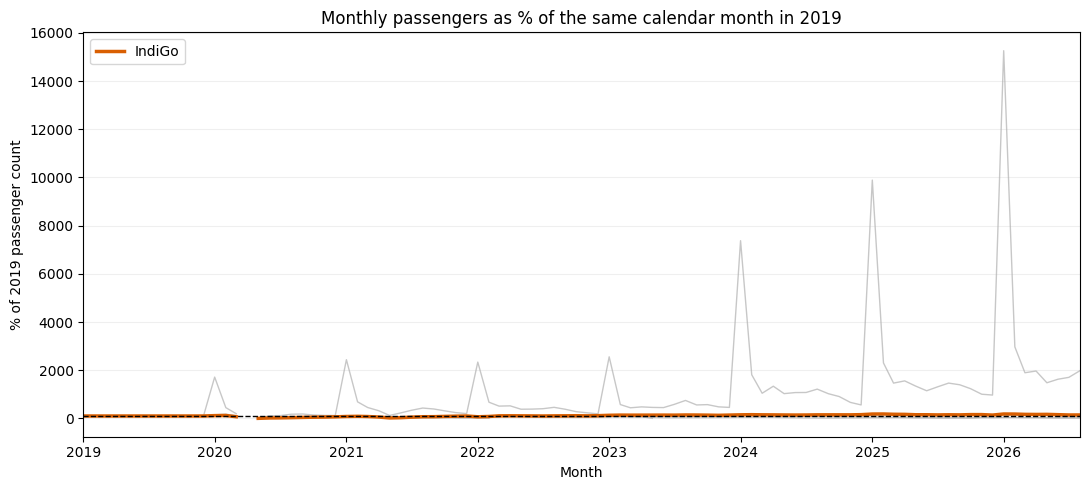

Figure saved: c:\Users\subhranshu das\OneDrive\Desktop\DGCA_aviation_analysis\outputs\figures\passenger_recovery_2026-11-01.png


In [10]:
# BLOCK 10: load factor 2019 vs after (weighted: sum PKP / sum SKP, not an average of percentages) + one plot
# Calculate annual weighted passenger load factor
lf = sdc.groupby([
    "Group", sdc.Date.dt.year.rename("Year")
])[["Passenger Kilometers", "Seat Kilometers"]].sum(min_count=1)

lf["Load Factor"] = (
    lf["Passenger Kilometers"]
    / lf["Seat Kilometers"].where(lf["Seat Kilometers"] > 0)
    * 100
)

tbl = lf["Load Factor"].unstack("Year").reindex(res.Group)
years = [y for y in [2019, 2022, 2023, 2024, 2025, 2026] if y in tbl.columns]

print("Annual weighted load factor (%):")
display(tbl[years].round(1))

# Plot passenger recovery, highlighting IndiGo
HIGHLIGHT = "IndiGo"
fig, ax = plt.subplots(figsize=(11, 5))

for grp in ratio.columns:
    if grp != HIGHLIGHT:
        ax.plot(ratio.index, ratio[grp] * 100, color="#b0b0b0", lw=1, alpha=0.7)

if HIGHLIGHT in ratio.columns:
    ax.plot(
        ratio.index, ratio[HIGHLIGHT] * 100,
        color="#d95f02", lw=2.5, label=HIGHLIGHT
    )

ax.axhline(100, color="black", ls="--", lw=1)
ax.set_xlim(pd.Timestamp("2019-01-01"), ratio.index.max())
ax.set_title("Monthly passengers as % of the same calendar month in 2019")
ax.set_xlabel("Month")
ax.set_ylabel("% of 2019 passenger count")

if HIGHLIGHT in ratio.columns:
    ax.legend()

ax.grid(axis="y", alpha=0.2)
plt.tight_layout()

# Save figure
FIGURES = PROJECT_ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

fig_path = FIGURES / f"passenger_recovery_{TODAY}.png"
fig.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("Figure saved:", fig_path)

In [11]:
# Final data-quality checks
print("FINAL DATA QUALITY SUMMARY")

print("Rows:", len(clean), "| Columns:", len(clean.columns))
print("Duplicate keys:", int(clean.duplicated(["Type", "Airline", "Date"]).sum()))
print("Missing values in core metrics:", int(clean[core].isna().sum().sum()))
print("Negative values in core metrics:", int(clean[core].lt(0).sum().sum()))
print("Outlier flags:", len(out))
print("Rule-based flags:", len(rule_flags))
print("Analysis cutoff:", ANALYSIS_END.strftime("%Y-%m"))

print("Saved clean dataset:", parquet_path.exists())
print("Saved dictionary:", dictionary_path.exists())
print("Saved cleaning log:", log_path.exists())

FINAL DATA QUALITY SUMMARY
Rows: 1957 | Columns: 15
Duplicate keys: 0
Missing values in core metrics: 128
Negative values in core metrics: 0
Outlier flags: 53
Rule-based flags: 4
Analysis cutoff: 2026-08
Saved clean dataset: True
Saved dictionary: True
Saved cleaning log: True
